# Preparação de Dados e Baseline de Persistência

Este notebook aborda os seguintes tópicos solicitados:
- **Tópico 3**: Carga do dataset `dados_modelo_2.csv`, split temporal isolando as safras de 2023-2024 para teste e escalonamento seguro das variáveis climáticas com `ColumnTransformer` (evitando *data leakage*).
- **Tópico 4**: Construção de um modelo baseline de Persistência (utilizando `.shift(1)`) e avaliação nos dados de teste através da Matriz de Confusão, Precision, Recall e F1-Score.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

## Tópico 3: Carga, Split Temporal e Escalonamento Seguro

In [6]:
# 1. Carga de Dados
df = pd.read_csv("../data/processed/dados_modelo.csv")

# Garantir que os dados estão ordenados por ano para o shift funcionar corretamente e manter a coerência temporal
df = df.sort_values("ano").reset_index(drop=True)

# 2. Definição do Split Temporal (2023-2024 isolados para teste)
train_mask = df["ano"] < 2023
test_mask = df["ano"] >= 2023

df_train = df[train_mask].copy()
df_test = df[test_mask].copy()

print(f"Amostras no Treino (até 2022): {df_train.shape[0]}")
print(f"Amostras no Teste (2023-2024): {df_test.shape[0]}\n")

# 3. Configuração do ColumnTransformer (Escalonamento sem Data Leakage)
# Variáveis climáticas mapeadas diretamente do novo dataset
variaveis_climaticas = [
    'PRECTOTCORR', 'T2M', 'T2M_MAX', 'T2M_MIN', 
    'RH2M', 'GWETROOT', 'amplitude_termica', 
    'precipitacao_por_temperatura', 'GWET_x_PREC'
]

# Criamos o transformador para aplicar StandardScaler apenas nas climáticas,
# repassando o restante das colunas inalteradas (remainder='passthrough')
preprocessor = ColumnTransformer(
    transformers=[
        ("climatic_scaler", StandardScaler(), variaveis_climaticas)
    ],
    remainder="passthrough"
)

# O fit_transform() é aplicado APENAS nos dados de treino para aprender os parâmetros de escala.
X_train_scaled = preprocessor.fit_transform(df_train)

# O transform() é aplicado nos dados de teste utilizando as métricas do treino.
X_test_scaled = preprocessor.transform(df_test)

print("Escalonamento das variáveis climáticas concluído com sucesso!")

Amostras no Treino (até 2022): 8
Amostras no Teste (2023-2024): 2

Escalonamento das variáveis climáticas concluído com sucesso!


## Tópico 4: Modelo Baseline de Persistência e Métricas de Validação

--- RESULTADOS DO MODELO DE PERSISTÊNCIA (BASELINE) ---
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000



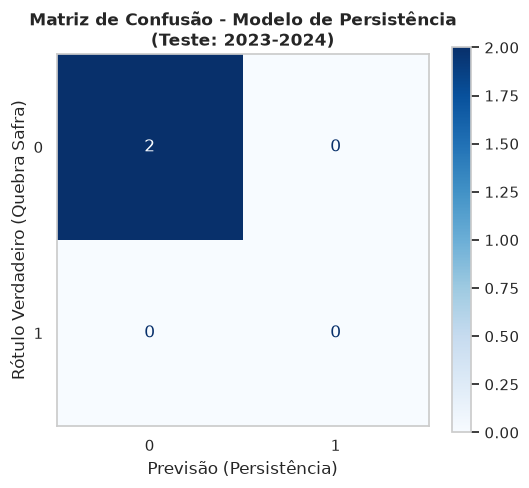

In [7]:
# Variável alvo real baseada no dataset fornecido
target = "quebra_safra"

# 1. Construção da Persistência usando .shift(1)
# A previsão para o ano N será igual à ocorrência real no ano N-1
df["predicao_persistencia"] = df[target].shift(1)

# 2. Isolando as previsões do Baseline apenas para o nosso período de Teste (2023-2024)
df_test_eval = df[df["ano"] >= 2023].copy()
df_test_eval = df_test_eval.dropna(subset=["predicao_persistencia"])

y_true = df_test_eval[target]
y_pred = df_test_eval["predicao_persistencia"]

# 3. Cálculo das Métricas de Validação (Classificação)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("--- RESULTADOS DO MODELO DE PERSISTÊNCIA (BASELINE) ---")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

# 4. Plotagem da Matriz de Confusão
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=True)

ax.set_title("Matriz de Confusão - Modelo de Persistência\n(Teste: 2023-2024)", fontweight="bold")
ax.set_xlabel("Previsão (Persistência)")
ax.set_ylabel("Rótulo Verdadeiro (Quebra Safra)")
plt.grid(False)
plt.show()